# Dự đoán giá trị cầu thủ FIFA 21

Notebook xây dựng baseline Machine Learning để dự đoán `value_eur` từ thông tin cầu thủ. Chạy các cell theo thứ tự từ trên xuống dưới; đặt `players_21.csv.zip` ở thư mục làm việc hiện tại.

**Quy trình:** đọc và làm sạch dữ liệu → EDA → chuẩn bị features/target → chia train/test → pipeline tiền xử lý → so sánh Dummy median, Ridge và Random Forest bằng 5-fold cross-validation → đánh giá mô hình tốt nhất trên test set → phân tích feature importance → lưu mô hình và thử dự đoán cầu thủ theo `sofifa_id`.

**Phạm vi target:** phiên bản baseline chỉ huấn luyện trên các cầu thủ có `value_eur > 0`. Giá trị dự đoán là ước lượng dựa trên dataset FIFA 21, không phải định giá thị trường hiện tại.


**1. Đọc và kiểm tra dữ liệu**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("players_21.csv.zip", low_memory=False)

# Chuẩn hóa tên cột
df.columns = df.columns.str.strip()

print("Kích thước:", df.shape)
print("\n5 dòng đầu:")
display(df.head())

print("\nKiểu dữ liệu:")
print(df.dtypes)

print("\nSố giá trị thiếu theo cột:")
print(df.isna().sum().sort_values(ascending=False).head(20))

print("\nSố dòng trùng hoàn toàn:", df.duplicated().sum())

print("\nCác cột:")
print(df.columns.tolist())


Kích thước: (18944, 106)

5 dòng đầu:


,sofifa_id,player_url,short_name,long_name,age,dob,height_cm,weight_kg,nationality,club_name,...,lwb,ldm,cdm,rdm,rwb,lb,lcb,cb,rcb,rb
0,158023,https://sofifa.com/player/158023/lionel-messi/...,L. Messi,Lionel Andrés Messi Cuccittini,33,1987-06-24,170,72,Argentina,FC Barcelona,...,66+3,65+3,65+3,65+3,66+3,62+3,52+3,52+3,52+3,62+3
1,20801,https://sofifa.com/player/20801/c-ronaldo-dos-...,Cristiano Ronaldo,Cristiano Ronaldo dos Santos Aveiro,35,1985-02-05,187,83,Portugal,Juventus,...,65+3,61+3,61+3,61+3,65+3,61+3,54+3,54+3,54+3,61+3
2,200389,https://sofifa.com/player/200389/jan-oblak/210002,J. Oblak,Jan Oblak,27,1993-01-07,188,87,Slovenia,Atlético Madrid,...,32+3,36+3,36+3,36+3,32+3,32+3,33+3,33+3,33+3,32+3
3,188545,https://sofifa.com/player/188545/robert-lewand...,R. Lewandowski,Robert Lewandowski,31,1988-08-21,184,80,Poland,FC Bayern München,...,64+3,65+3,65+3,65+3,64+3,61+3,60+3,60+3,60+3,61+3
4,190871,https://sofifa.com/player/190871/neymar-da-sil...,Neymar Jr,Neymar da Silva Santos Júnior,28,1992-02-05,175,68,Brazil,Paris Saint-Germain,...,67+3,62+3,62+3,62+3,67+3,62+3,49+3,49+3,49+3,62+3



Kiểu dữ liệu:
sofifa_id      int64
player_url    object
short_name    object
long_name     object
age            int64
               ...  
lb            object
lcb           object
cb            object
rcb           object
rb            object
Length: 106, dtype: object

Số giá trị thiếu theo cột:
defending_marking       18944
loaned_from             18186
nation_jersey_number    17817
nation_position         17817
player_tags             17536
gk_kicking              16861
gk_diving               16861
gk_positioning          16861
gk_reflexes             16861
gk_handling             16861
gk_speed                16861
player_traits           10629
dribbling                2083
defending                2083
physic                   2083
shooting                 2083
passing                  2083
pace                     2083
release_clause_eur        995
joined                    983
dtype: int64

Số dòng trùng hoàn toàn: 0

Các cột:
['sofifa_id', 'player_url', 'short_name', 'long_

**2. Làm sạch dữ liệu**

In [3]:
# Các cột cơ bản cần có
required_cols = {
    "value_eur",
    "age",
    "overall",
    "potential",
    "pace"
}

missing_cols = required_cols - set(df.columns)

if missing_cols:
    raise ValueError(
        f"Thiếu các cột cần thiết: {missing_cols}. "
        "Hãy kiểm tra đúng file players_21.csv."
    )

# Chuyển target sang dạng số
df["value_eur"] = pd.to_numeric(
    df["value_eur"],
    errors="coerce"
)

# Loại những dòng không có target hợp lệ
df = df.dropna(subset=["value_eur"])
df = df[df["value_eur"] >= 0].copy()

# Nếu có ID cầu thủ, kiểm tra và loại ID trùng
if "sofifa_id" in df.columns:
    df = df.drop_duplicates(
        subset=["sofifa_id"],
        keep="first"
    )
else:
    df = df.drop_duplicates()

# Phạm vi phiên bản đầu: cầu thủ ngoài vị trí thủ môn
df = df[df["pace"].notna()].copy()

# Chuẩn hóa index sau khi lọc
df = df.reset_index(drop=True)

zero_value = df["value_eur"].eq(0)

print("Số cầu thủ có value bằng 0:", zero_value.sum())

display(
    df.loc[
        zero_value,
        ["short_name", "age", "overall",
         "potential", "value_eur"]
    ].head(20)
)

print("Kích thước sau làm sạch:", df.shape)
print("Giá trị target thiếu:", df["value_eur"].isna().sum())
print("Giá trị target nhỏ nhất:", df["value_eur"].min())
print("Giá trị target lớn nhất:", df["value_eur"].max())

Số cầu thủ có value bằng 0: 207


,short_name,age,overall,potential,value_eur
301,Juiano Mestres,24,81,81,0
305,Welington Dano,20,81,81,0
423,J. Frendado,36,80,80,0
424,M. Baldona,36,80,80,0
425,S. Ardero,32,80,80,0
426,L. Dálves,28,80,80,0
427,M. Nérez,32,80,80,0
428,E. Schetino,28,80,80,0
429,J. Sildero,28,80,80,0
430,S. Mandíquez,31,80,80,0


Kích thước sau làm sạch: (16861, 106)
Giá trị target thiếu: 0
Giá trị target nhỏ nhất: 0
Giá trị target lớn nhất: 105500000


In [4]:
# Lưu lại các dòng value = 0 để kiểm tra và báo cáo
zero_value_players = df.loc[
    df["value_eur"] == 0
].copy()

# Tạo dataset cho bài toán dự đoán giá trị dương
df_model = df.loc[
    df["value_eur"] > 0
].copy()

df_model = df_model.reset_index(drop=True)

print("Số dòng ban đầu:", len(df))
print("Số dòng value = 0:", len(zero_value_players))
print("Số dòng dùng để train:", len(df_model))
print("Giá trị target nhỏ nhất:", df_model["value_eur"].min())

Số dòng ban đầu: 16861
Số dòng value = 0: 207
Số dòng dùng để train: 16654
Giá trị target nhỏ nhất: 20000


**3. EDA — Khám phá dữ liệu**

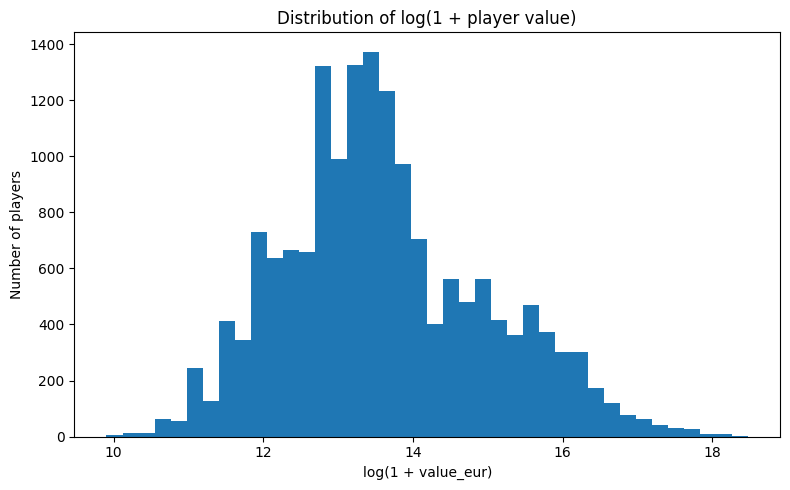

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(
    np.log1p(df_model["value_eur"]),
    bins=40
)

plt.title("Distribution of log(1 + player value)")
plt.xlabel("log(1 + value_eur)")
plt.ylabel("Number of players")
plt.tight_layout()
plt.show()

**4. Mối quan hệ giữa overall và giá trị**

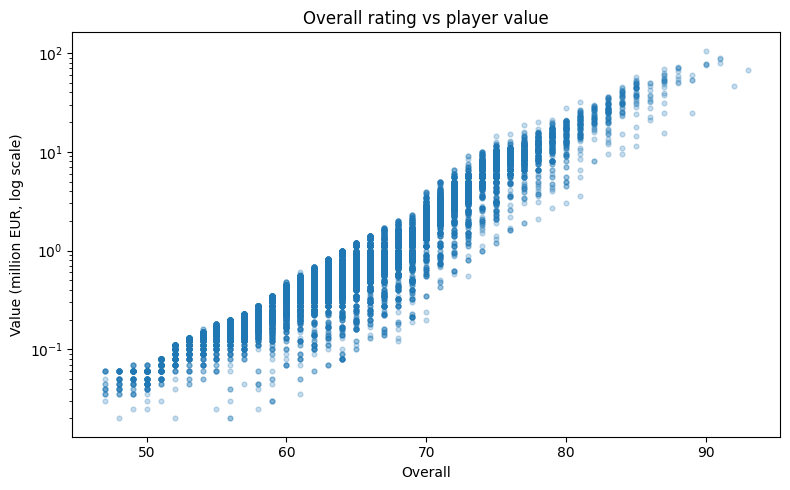

In [6]:
plot_df = df_model[["overall", "value_eur"]].copy()

plt.figure(figsize=(8, 5))

plt.scatter(
    plot_df["overall"],
    plot_df["value_eur"] / 1_000_000,
    alpha=0.25,
    s=12
)

plt.yscale("log")
plt.title("Overall rating vs player value")
plt.xlabel("Overall")
plt.ylabel("Value (million EUR, log scale)")
plt.tight_layout()
plt.show()

**5. Tuổi và giá trị**

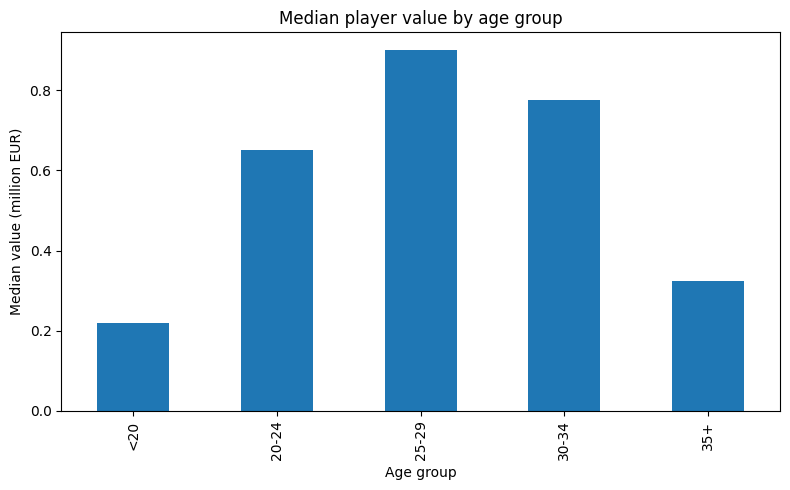

age_group
<20      0.220
20-24    0.650
25-29    0.900
30-34    0.775
35+      0.325
Name: value_eur, dtype: float64


In [7]:
df_model["age_group"] = pd.cut(
    df_model["age"],
    bins=[0, 20, 25, 30, 35, 100],
    right=False,
    labels=["<20", "20-24", "25-29", "30-34", "35+"]
)

age_median = (
    df_model.groupby("age_group", observed=False)["value_eur"]
    .median()
    / 1_000_000
)

plt.figure(figsize=(8, 5))
age_median.plot(kind="bar")

plt.title("Median player value by age group")
plt.xlabel("Age group")
plt.ylabel("Median value (million EUR)")
plt.tight_layout()
plt.show()

print(age_median)

**6. Kiểm tra các đặc trưng tương quan**

In [8]:
corr_candidates = [
    "value_eur",
    "age",
    "overall",
    "potential",
    "pace",
    "shooting",
    "passing",
    "dribbling",
    "defending",
    "physic"
]

corr_cols = [
    col for col in corr_candidates
    if col in df_model.columns
]

corr = df_model[corr_cols].corr(
    method="spearman"
)["value_eur"].sort_values(ascending=False)

print(corr)

value_eur    1.000000
overall      0.950177
potential    0.738417
dribbling    0.692012
passing      0.674757
shooting     0.498062
physic       0.445435
defending    0.334013
pace         0.314461
age          0.262335
Name: value_eur, dtype: float64


**7. Chuẩn bị feature và target**

In [9]:
# 1. Danh sách các cột số
NUMERIC_CANDIDATES = [
    "age",
    "overall",
    "potential",
    "height_cm",
    "weight_kg",
    "international_reputation",
    "weak_foot",
    "skill_moves",

    "pace",
    "shooting",
    "passing",
    "dribbling",
    "defending",
    "physic",

    "attacking_crossing",
    "attacking_finishing",
    "attacking_heading_accuracy",
    "attacking_short_passing",
    "attacking_volleys",

    "skill_dribbling",
    "skill_curve",
    "skill_fk_accuracy",
    "skill_long_passing",
    "skill_ball_control",

    "movement_acceleration",
    "movement_sprint_speed",
    "movement_agility",
    "movement_reactions",
    "movement_balance",

    "power_shot_power",
    "power_jumping",
    "power_stamina",
    "power_strength",
    "power_long_shots",

    "mentality_aggression",
    "mentality_interceptions",
    "mentality_positioning",
    "mentality_vision",
    "mentality_penalties",
    "mentality_composure",

    "defending_marking_awareness",
    "defending_standing_tackle",
    "defending_sliding_tackle",

    "crossing",
    "finishing",
    "heading_accuracy",
    "short_passing",
    "volleys",
    "curve",
    "fk_accuracy",
    "long_passing",
    "ball_control",
    "acceleration",
    "sprint_speed",
    "agility",
    "reactions",
    "balance",
    "shot_power",
    "jumping",
    "stamina",
    "strength",
    "long_shots",
    "aggression",
    "interceptions",
    "positioning",
    "vision",
    "penalties",
    "composure",
    "marking",
    "standing_tackle",
    "sliding_tackle"
]

# 2. Danh sách các cột phân loại
CATEGORICAL_CANDIDATES = [
    "player_positions",
    "preferred_foot",
    "work_rate"
]

# 3. Kiểm tra dataset
if "value_eur" not in df.columns:
    raise ValueError("Không tìm thấy cột value_eur trong dataset.")

# Loại bỏ tên cột trùng và chỉ giữ cột có trong dataset
numeric_features = list(dict.fromkeys(
    col for col in NUMERIC_CANDIDATES
    if col in df.columns and df[col].notna().any()
))

categorical_features = list(dict.fromkeys(
    col for col in CATEGORICAL_CANDIDATES
    if col in df.columns and df[col].notna().any()
))

# Chuẩn hóa cả dữ liệu dùng cho EDA và tập mô hình
for frame in (df, df_model):
    for col in numeric_features:
        frame[col] = pd.to_numeric(frame[col], errors="coerce")

    for col in categorical_features:
        frame[col] = frame[col].replace(
            r"^\s*$",
            np.nan,
            regex=True
        )

# 4. Tạo tập feature
full_features = list(dict.fromkeys(
    numeric_features + categorical_features
))

X = df_model[full_features].copy()
y = df_model["value_eur"].copy()

# 5. Kiểm tra
print("Số numeric features:", len(numeric_features))
print("Số categorical features:", len(categorical_features))
print("Tổng số features:", len(full_features))
print("Tên cột X có duy nhất không:", X.columns.is_unique)
print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

assert X.columns.is_unique, "X vẫn còn tên cột trùng!"

assert (y > 0).all(), "Tập target dùng cho model còn giá trị <= 0."
assert len(X) == len(y), "X và y không cùng số dòng."


Số numeric features: 42
Số categorical features: 3
Tổng số features: 45
Tên cột X có duy nhất không: True
Kích thước X: (16654, 45)
Kích thước y: (16654,)


**8. Chia train/test**

In [10]:
from sklearn.model_selection import train_test_split

# Chia các khoảng theo log của giá trị để cố gắng
# giữ phân phối target tương tự ở train và test
value_bins = pd.qcut(
    np.log1p(y),
    q=10,
    labels=False,
    duplicates="drop"
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=value_bins
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (13323, 45)
Test: (3331, 45)


**9. Xây dựng pipeline tiền xử lý**

In [11]:
from sklearn.compose import (
    ColumnTransformer,
    TransformedTargetRegressor
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


def build_preprocessor(
    num_cols,
    cat_cols,
    scale_numeric=False
):
    transformers = []

    if num_cols:
        numeric_steps = [
            ("imputer", SimpleImputer(strategy="median"))
        ]

        if scale_numeric:
            numeric_steps.append(
                ("scaler", StandardScaler())
            )

        numeric_pipeline = Pipeline(numeric_steps)

        transformers.append(
            ("num", numeric_pipeline, num_cols)
        )

    if cat_cols:
        categorical_pipeline = Pipeline([
            (
                "imputer",
                SimpleImputer(strategy="most_frequent")
            ),
            (
                "onehot",
                OneHotEncoder(handle_unknown="ignore")
            )
        ])

        transformers.append(
            ("cat", categorical_pipeline, cat_cols)
        )

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )


def build_log_model(
    estimator,
    num_cols,
    cat_cols,
    scale_numeric=False
):
    pipeline = Pipeline([
        (
            "preprocessor",
            build_preprocessor(
                num_cols,
                cat_cols,
                scale_numeric=scale_numeric
            )
        ),
        ("model", estimator)
    ])

    # Train theo log(1 + value_eur), predict trở lại EUR
    return TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1
    )


**10. Huấn luyện và so sánh mô hình**

10.1. Định nghĩa các cấu hình

In [12]:
base_features = [
    col for col in ["age", "overall", "potential"]
    if col in full_features
]

# Giữ các đặc trưng khác nhưng loại overall
detailed_no_overall_features = [
    col for col in full_features
    if col != "overall"
]

feature_sets = {
    "Base": base_features,
    "Detailed without overall": detailed_no_overall_features,
    "Full": full_features
}

for name, cols in feature_sets.items():
    print(name, "| số feature:", len(cols))

Base | số feature: 3
Detailed without overall | số feature: 44
Full | số feature: 45


10.2. Tạo danh sách model

In [13]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor

candidate_models = {}
candidate_features = {}

# Baseline không dựa vào các feature
candidate_models["Dummy median"] = DummyRegressor(
    strategy="median"
)
candidate_features["Dummy median"] = full_features

for feature_set_name, cols in feature_sets.items():

    num_cols = [
        col for col in cols
        if col in numeric_features
    ]

    cat_cols = [
        col for col in cols
        if col in categorical_features
    ]

    ridge_name = f"Ridge | {feature_set_name}"

    candidate_models[ridge_name] = build_log_model(
        Ridge(alpha=10.0),
        num_cols,
        cat_cols,
        scale_numeric=True
    )

    candidate_features[ridge_name] = cols

    rf_name = f"Random Forest | {feature_set_name}"

    candidate_models[rf_name] = build_log_model(
        RandomForestRegressor(
            n_estimators=150,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ),
        num_cols,
        cat_cols,
        scale_numeric=False
    )

    candidate_features[rf_name] = cols

10.3. Cross-validation trên train

In [14]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score

# Chia y_train thành các nhóm theo log giá trị
cv_bins = pd.qcut(
    np.log1p(y_train),
    q=5,
    labels=False,
    duplicates="drop"
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Tạo sẵn các fold để mọi mô hình dùng cùng cách chia
# Quan trọng: cross_val_score phải dùng chính các fold đã tạo từ cv_bins.
cv_splits = list(cv.split(X_train, cv_bins))
cv_results = []

for name, model in candidate_models.items():

    cols = candidate_features[name]

    scores = cross_val_score(
        model,
        X_train[cols],
        y_train,
        cv=cv_splits,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    fold_mae = -scores

    cv_results.append({
        "model": name,
        "mean_mae_eur": fold_mae.mean(),
        "std_mae_eur": fold_mae.std()
    })

results_df = (
    pd.DataFrame(cv_results)
    .sort_values("mean_mae_eur")
    .reset_index(drop=True)
)

display(results_df)

,model,mean_mae_eur,std_mae_eur
0,Random Forest | Full,1.050680e+05,7454.679488
1,Random Forest | Base,1.598413e+05,9614.623316
2,Random Forest | Detailed without overall,3.543125e+05,14041.190914
3,Ridge | Base,4.279269e+05,23716.652569
4,Ridge | Full,4.410908e+05,36518.576228
5,Ridge | Detailed without overall,6.745865e+05,39715.676705
6,Dummy median,1.997647e+06,58651.095598


Vẽ biểu đồ

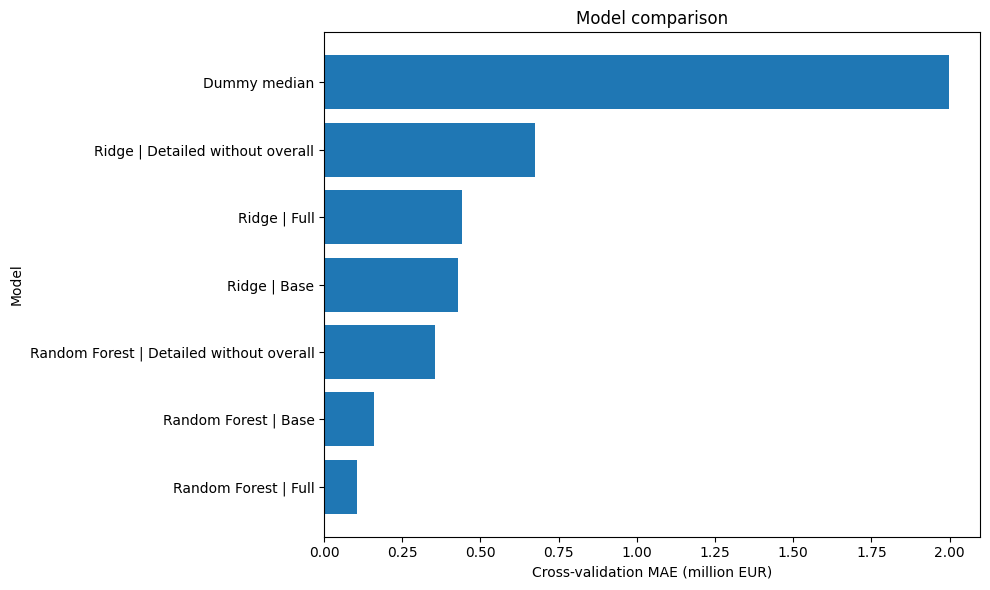

In [15]:
plt.figure(figsize=(10, 6))

plot_results = results_df.sort_values(
    "mean_mae_eur",
    ascending=True
)

plt.barh(
    plot_results["model"],
    plot_results["mean_mae_eur"] / 1_000_000
)

plt.xlabel("Cross-validation MAE (million EUR)")
plt.ylabel("Model")
plt.title("Model comparison")
plt.tight_layout()
plt.show()

**11. Đưa ra mô hình có kết quả tốt nhất**

In [26]:
# Chọn mô hình có CV MAE thấp nhất
best_name = results_df.loc[0, "model"]
best_features = candidate_features[best_name]
best_model = candidate_models[best_name]
best_cv_mae = results_df.loc[0, "mean_mae_eur"]

print("Mô hình được chọn:", best_name)
print(f"CV MAE: {best_cv_mae:,.0f} EUR")
print("Số lượng features:", len(best_features))

Mô hình được chọn: Random Forest | Full
CV MAE: 105,068 EUR
Số lượng features: 45


**12. Đánh giá trên tập test**

In [27]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

best_model.fit(
    X_train[best_features],
    y_train
)

y_pred = best_model.predict(
    X_test[best_features]
)

# Đề phòng sai số số học ở dự đoán
y_pred = np.maximum(y_pred, 0)

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

rmsle = np.sqrt(
    np.mean(
        (
            np.log1p(y_test.to_numpy())
            - np.log1p(y_pred)
        ) ** 2
    )
)

print("Model:", best_name)
print(f"Test MAE:  {mae:,.2f} EUR")
print(f"Test RMSE: {rmse:,.2f} EUR")
print(f"Test R²:   {r2:.4f}")
print(f"Test RMSLE: {rmsle:.4f}")

Model: Random Forest | Full
Test MAE:  103,673.43 EUR
Test RMSE: 734,528.59 EUR
Test R²:   0.9781
Test RMSLE: 0.0563


**12.1. Biểu đồ giá trị thực tế và giá trị dự đoán**

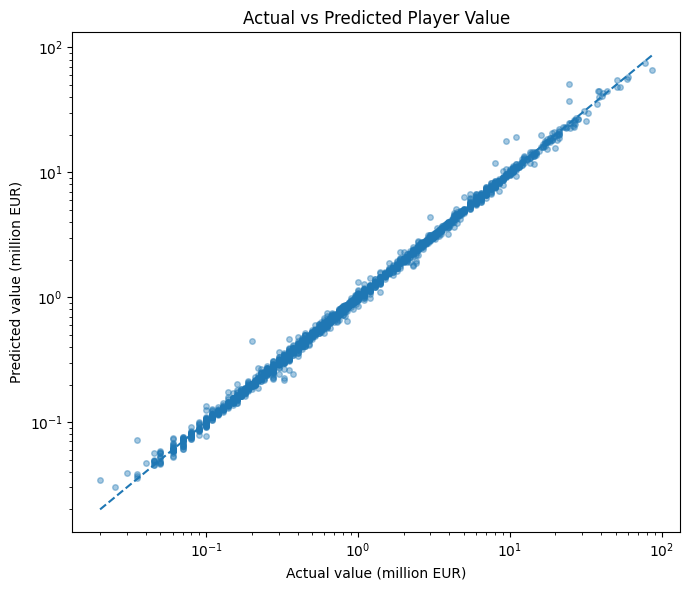

In [28]:
# So sánh giá trị thực tế với giá trị dự đoán trên test set
actual = np.asarray(y_test, dtype=float)
predicted = np.asarray(y_pred, dtype=float)

# Trục log không hiển thị được 0 hoặc số âm; bỏ qua các dự đoán không dương
# chỉ trong biểu đồ này. Các metric phía trên vẫn dùng toàn bộ test set.
plot_mask = (actual > 0) & (predicted > 0)
if plot_mask.sum() == 0:
    print("Không có cặp actual/predicted dương để vẽ trên trục log.")
else:
    actual_plot = actual[plot_mask] / 1_000_000
    predicted_plot = predicted[plot_mask] / 1_000_000

    plt.figure(figsize=(7, 6))
    plt.scatter(
        actual_plot,
        predicted_plot,
        alpha=0.4,
        s=16
    )

    lower = min(actual_plot.min(), predicted_plot.min())
    upper = max(actual_plot.max(), predicted_plot.max())
    plt.plot([lower, upper], [lower, upper], linestyle="--")

    plt.xscale("log")
    plt.yscale("log")
    plt.xlabel("Actual value (million EUR)")
    plt.ylabel("Predicted value (million EUR)")
    plt.title("Actual vs Predicted Player Value")
    plt.tight_layout()
    plt.show()


**12.2. Sai số theo nhóm giá trị cầu thủ**

Tập test được chia thành tối đa bốn nhóm theo giá trị thực tế. Biểu đồ giúp kiểm tra MAE có tăng ở nhóm cầu thủ giá trị cao hay không.


,price_group,n,median_value_eur,MAE_eur,median_absolute_error_eur
0,"(19999.999, 325000.0]",861,180000.0,6383.228832,3047.072905
1,"(325000.0, 675000.0]",818,500000.0,11909.243845,6734.574942
2,"(675000.0, 1900000.0]",827,1000000.0,26154.316867,13240.148395
3,"(1900000.0, 87000000.0]",825,5000000.0,373901.637745,97783.122953


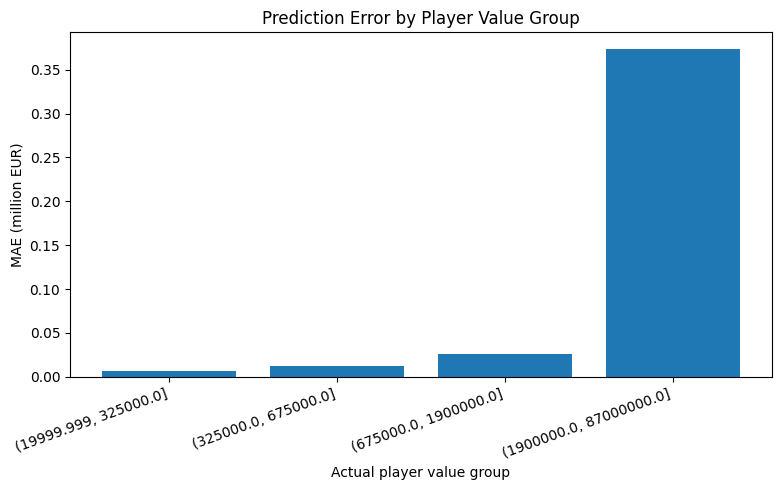

In [29]:
error_df = pd.DataFrame({
    "actual_value_eur": np.asarray(y_test, dtype=float),
    "predicted_value_eur": np.asarray(y_pred, dtype=float)
})
error_df["absolute_error_eur"] = (
    error_df["actual_value_eur"] - error_df["predicted_value_eur"]
).abs()

# Chia test set thành các nhóm theo giá trị thực tế; duplicates='drop'
# phòng trường hợp quantile boundaries bị trùng.
error_df["price_group"] = pd.qcut(
    error_df["actual_value_eur"],
    q=4,
    duplicates="drop"
)

error_summary = (
    error_df.groupby("price_group", observed=True)
    .agg(
        n=("actual_value_eur", "size"),
        median_value_eur=("actual_value_eur", "median"),
        MAE_eur=("absolute_error_eur", "mean"),
        median_absolute_error_eur=("absolute_error_eur", "median")
    )
    .reset_index()
)

display(error_summary)

plt.figure(figsize=(8, 5))
plt.bar(
    error_summary["price_group"].astype(str),
    error_summary["MAE_eur"] / 1_000_000
)
plt.xlabel("Actual player value group")
plt.ylabel("MAE (million EUR)")
plt.title("Prediction Error by Player Value Group")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


**12.3. Xem một số dự đoán cụ thể**


In [30]:
metadata_cols = [
    col for col in ["short_name", "club_name"]
    if col in df_model.columns
]

pred_table = df_model.loc[
    X_test.index,
    metadata_cols
].copy()

pred_table["actual_value_eur"] = y_test
pred_table["predicted_value_eur"] = y_pred

pred_table["absolute_error_eur"] = (
    pred_table["actual_value_eur"]
    - pred_table["predicted_value_eur"]
).abs()

display(
    pred_table.sort_values(
        "absolute_error_eur",
        ascending=False
    ).head(15)
)

,short_name,club_name,actual_value_eur,predicted_value_eur,absolute_error_eur
10,Sergio Ramos,Real Madrid,24500000,5.082647e+07,2.632647e+07
4,K. De Bruyne,Manchester City,87000000,6.624849e+07,2.075151e+07
30,L. Modrić,Real Madrid,24500000,3.702902e+07,1.252902e+07
103,Fernandinho,Manchester City,9500000,1.776150e+07,8.261499e+06
104,Jesús Navas,Sevilla FC,11000000,1.922252e+07,8.222517e+06
33,Sergio Busquets,FC Barcelona,38000000,4.451258e+07,6.512583e+06
226,João Félix,Atlético Madrid,32000000,2.568790e+07,6.312097e+06
31,A. Di María,Paris Saint-Germain,39000000,4.456872e+07,5.568720e+06
52,M. Rashford,Manchester United,53000000,4.854021e+07,4.459791e+06
578,Trincão,FC Barcelona,20000000,1.563049e+07,4.369507e+06


**13. Phân tích những feature hữu ích cho dự đoán**

In [31]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test[best_features],
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "feature": best_features,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

display(importance_df.head(15))

,feature,importance_mean,importance_std
1,overall,2.401972e+06,44607.092661
2,potential,7.284821e+05,12951.609049
0,age,2.129218e+05,3611.700368
15,attacking_finishing,1.030956e+04,397.061519
41,defending_sliding_tackle,9.947493e+03,750.352714
9,shooting,7.709415e+03,386.745868
12,defending,6.592357e+03,332.052409
40,defending_standing_tackle,3.949685e+03,530.603325
35,mentality_interceptions,2.739550e+03,322.940744
36,mentality_positioning,2.569731e+03,102.076517


Vẽ biểu đồ

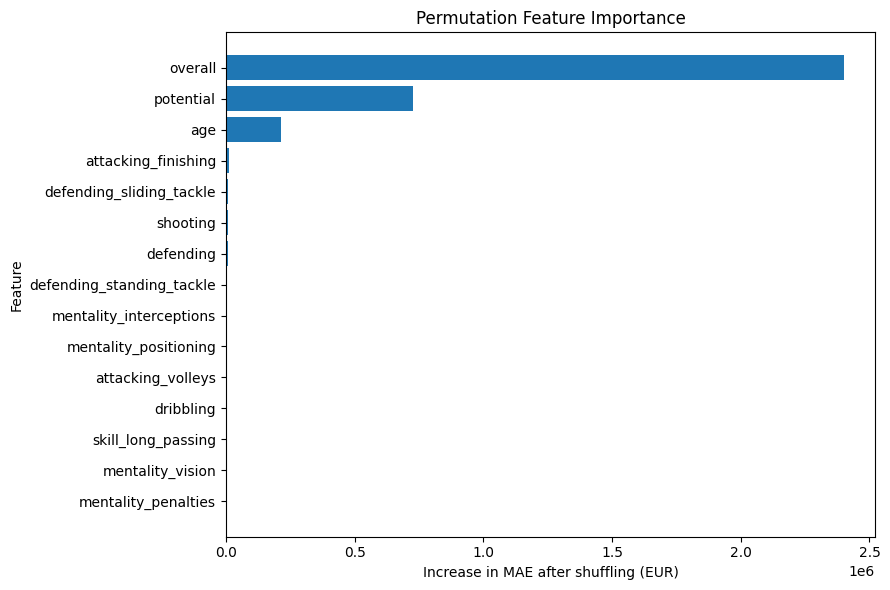

In [32]:
top_features = (
    importance_df.head(15)
    .sort_values("importance_mean")
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["feature"],
    top_features["importance_mean"]
)

plt.xlabel("Increase in MAE after shuffling (EUR)")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance")
plt.tight_layout()
plt.show()

**14. Lưu model và tạo sản phẩm hoàn chỉnh**

In [33]:
import joblib
from pathlib import Path

Path("models").mkdir(exist_ok=True)

bundle = {
    "model": best_model,
    "features": best_features,
    "target": "value_eur",
    "dataset": "FIFA 21 player dataset"
}

joblib.dump(
    bundle,
    "models/fifa_player_value_model.joblib"
)

print("Đã lưu model.")

Đã lưu model.


**15. Tìm ID cầu thủ muốn dự đoán**

In [51]:
# Tìm cầu thủ theo tên trong dataset đã làm sạch
player_name = "messi"

candidates = df_model[
    df_model["short_name"].str.contains(
        player_name,
        case=False,
        na=False
    )
]

display(
    candidates[
        [
            "sofifa_id",
            "short_name",
            "age",
            "overall",
            "potential",
            "value_eur"
        ]
    ]
)

,sofifa_id,short_name,age,overall,potential,value_eur
0,158023,L. Messi,33,93,93,67500000
8843,233774,A. Messidoro,23,65,71,750000
10521,240938,Junior Messias,29,64,64,450000
10940,236341,N. Messiniti,24,63,70,525000


Dự đoán giá cầu thủ

In [52]:
loaded_bundle = joblib.load(
    "models/fifa_player_value_model.joblib"
)

loaded_model = loaded_bundle["model"]
loaded_features = loaded_bundle["features"]

chosen_id = 158023

player = df_model.loc[
    df_model["sofifa_id"] == chosen_id
]

if player.empty:
    raise ValueError("Không tìm thấy Messi trong df_model.")

# Lấy đúng các đặc trưng mô hình cần
player_X = player[loaded_features]

# Dự đoán giá trị
predicted_value = float(
    loaded_model.predict(player_X)[0]
)

actual_value = float(
    player["value_eur"].iloc[0]
)

print("Cầu thủ:", player["short_name"].iloc[0])
print("SoFIFA ID:", chosen_id)
print("Overall:", player["overall"].iloc[0])
print("Potential:", player["potential"].iloc[0])
print(f"Giá trị dự đoán:     €{predicted_value:,.0f}")
print(f"Giá trị trong dataset: €{actual_value:,.0f}")
print(
    f"Sai số tuyệt đối:     "
    f"€{abs(predicted_value - actual_value):,.0f}"
)

Cầu thủ: L. Messi
SoFIFA ID: 158023
Overall: 93
Potential: 93
Giá trị dự đoán:     €66,783,278
Giá trị trong dataset: €67,500,000
Sai số tuyệt đối:     €716,722
